## **Analysis Notebook**

#### **Major question**

> **Did India's economy become substantially larger between May 2004-May2014 and May 2014-May2024?**

When working with macroeconomic datasets, we need to understand these six core metrics to handle the vast majority of economic data task:

GDP Variations:
```text
1. GDP growth (annual%)
2. GDP (current US$/LCU) AKA (Nominal GDP)
3. GDP (constant US$/LCU) AKA (Real GDP)
4. GDP per capita
5. GDP, PPP (Purchasing Power Parity)
6. Inflation, GDP deflator
7. Compound Growth of real GDP - CAGR (Compound Annual Growth Rate)
```
Explainations for each terms will be held in "Terms_explaination.md" file.

#### **Required Modules**

In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import os

#### **Subquestions**
1. **How did India's GDP change in absolute terms?**
- GDP at the beginning and end of each period
- Absolute increase in GDP
- Percentage increase in GDP
- How large was the economy at the end of each period?

let's find out each one....

#### **Data Ingestion**

In [3]:
# file path
file_path: str = 'Cleaned_datasets/Production/production_GDP_dataset.parquet'

if not os.path.exists(file_path):
    raise FileNotFoundError (f'{file_path} does not exist!')

try:
    df = pd.read_parquet(file_path)
    print(f'Successfully Loaded the file containing {len(df)} number of rows')
except Exception as e:
    print(f'Failed to read parquet file: {file_path}')
    raise

Successfully Loaded the file containing 21 number of rows


In [4]:
df.tail()

,Year,Inflation(annual %),GDP_Current(US$ Trillion),GDP_Constant(2015 US$ Trillion),GDP_Growth(annual%),GDP_PPP(Current US$ Trillion),GDP_Per_Capita(Current US$)
16,2020,4.81,2.67,2.53,-5.78,9.49,1907.04
17,2021,8.35,3.17,2.78,9.69,11.06,2239.61
18,2022,2.85,3.25,2.99,7.61,12.74,2279.98
19,2023,3.51,3.50,3.21,7.21,14.17,2434.45
20,2024,2.47,3.76,3.43,7.10,15.55,2591.99


#### **GDP at the beginning and end of each period**

| **Period** | **Beginning GDP year** | **Ending GDP year** |
|------------|------------------------|---------------------|
| **Period 1** | 2004 | 2014 |
| **Period 2** | 2014 | 2024 |

In [5]:
# Beginning of Period 1 
gdp_2004 = df.loc[df['Year']==2004, 'GDP_Current(US$ Trillion)'].item()

# Transition period it would be Ending Period for 'period 1' and Starting
# Period for 'Period 2' 
gdp_2014 = df.loc[df['Year']==2014, 'GDP_Current(US$ Trillion)'].item()

# Ending Period of Period 2
gdp_2024 = df.loc[df['Year']==2024, 'GDP_Current(US$ Trillion)'].item()

print(f'Current GDP for Period 1 Beginning = ${gdp_2004} Trillion And Ending = ${gdp_2014} Trillion')
print(f'Current GDP for Period 2 Beginning = ${gdp_2014} Trillion And Ending = ${gdp_2024} Trillion')

Current GDP for Period 1 Beginning = $0.71 Trillion And Ending = $2.04 Trillion
Current GDP for Period 2 Beginning = $2.04 Trillion And Ending = $3.76 Trillion


**Absolute Increase of GDP**

- Period 1 = GDP of 2014 - GDP of 2004

- Period 2 = GDP of 2024 - GDP of 2014

In [6]:
# For period 1
abs_gdp_increase_period_1 = gdp_2014 - gdp_2004

# For period 2
abs_gdp_increase_period_2 = gdp_2024 - gdp_2014

print(f'Absolute increase on GDP for Period 1: ${round(abs_gdp_increase_period_1, 2)} Trillion')
print(f'Absolute increase on GDP for Period 2: ${round(abs_gdp_increase_period_2, 2)} Trillion')

Absolute increase on GDP for Period 1: $1.33 Trillion
Absolute increase on GDP for Period 2: $1.72 Trillion


#### **Percentage Increase in GDP**

- Period 1 = (gdp_2014 - gdp_2004) / gdp_2004 x 100

- Period 2 = (gdp_2024 - gdp_2014) / gdp_2014 x 100

In [7]:
# For Period 1
per_gdp_increase_period_1 = round(((gdp_2014 - gdp_2004) / gdp_2004) * 100, 2)

# For Period 2
per_gdp_increase_period_2 = round(((gdp_2024 - gdp_2014) / gdp_2014) * 100, 2)
 
print(f'Absolute Percentage increase in GDP during Period 1: {per_gdp_increase_period_1}%')
print(f'Absolute Percentage increase in GDP during Period 2: {per_gdp_increase_period_2}%')

Absolute Percentage increase in GDP during Period 1: 187.32%
Absolute Percentage increase in GDP during Period 2: 84.31%


#### **How large was the economy at the end of each period**

- Period 1 : Total GDP of the year 2014 i.e. **$2.04 Trillion**

- Period 2 : Total GDP of the year 2024 i.3. **$3.76 Trillion**

#### **Annotated slop chart / endpoint comparison chart**

**2004 -> 2014**

- Beginning GDP = $0.71T
- Ending GDP = $2.04T
- Absolute increase = +$1.33T
- Percentage increase = +187.32%

**2014 -> 2024**

- Beginning GDP = $2.04T
- Ending GDP = $3.76T
- Absolute increase = +$1.72T
- Percentage increase = +84.31%



findfont: Failed to find font weight medium for DejaVu Sans, now using 400.


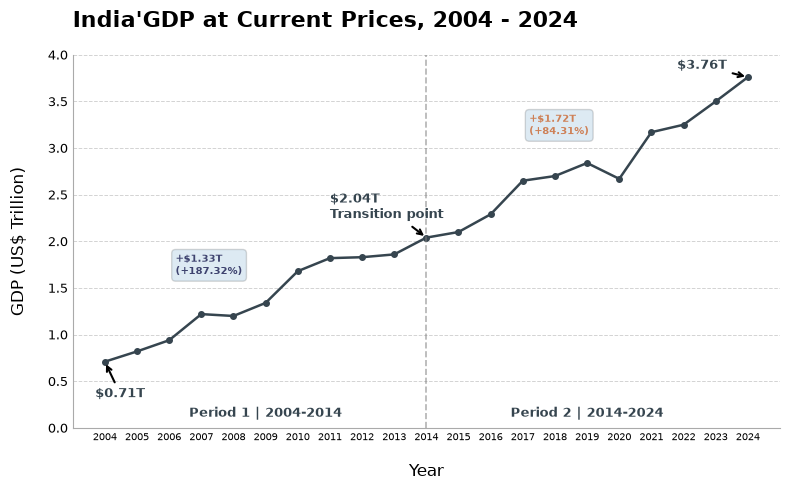

In [8]:
# Developing the Figure and Axes, we need two line charts.
fig, ax = plt.subplots(figsize=(8, 5))

ax.plot(
    df['Year'],
    df['GDP_Current(US$ Trillion)'],
    color='#36454F',
    linewidth=1.8,
    marker='o',
    markersize=4
)

# Format Axes and Labels
ax.set_title('India\'GDP at Current Prices, 2004 - 2024', fontsize=16, fontweight='bold', pad=20, loc='left')
ax.set_xlabel('Year', fontsize=12, fontweight='medium', labelpad=15)
ax.set_ylabel('GDP (US$ Trillion)', fontsize=12, fontweight='medium', labelpad=15)

ax.set_ylim(0, 4)
# Clean up the ticks
ax.tick_params(axis='x', which='major', labelsize=7, length=0)
ax.tick_params(axis='y', which='major', labelsize=9, length=0)
ax.set_xticks(df['Year'])

# add a subtle horizontal grid.
# zorder=0 pushes the grid behind the lines
ax.grid(axis='y', color='#d3d3d3', linestyle='--', linewidth=0.7, zorder=0)

# Strip away the top and right spines
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.spines['left'].set_color('#aaaaaa')
ax.spines['bottom'].set_color('#aaaaaa')


# Annotations
ax.annotate(
    '$0.71T',
    xy=(2004, 0.71),
    xytext=(2003.7, 0.33),
    arrowprops=dict(arrowstyle='->', lw=1.5),
    fontsize=9,
    fontweight='bold',
    color='#36454F'
)

ax.annotate(
    '$2.04T\nTransition point',
    xy=(2014, 2.04),
    xytext=(2011, 2.25),
    arrowprops=dict(arrowstyle='->', lw=1.5),
    fontsize=9,
    fontweight='bold',
    color='#36454F'
)

ax.annotate(
    '$3.76T',
    xy=(2024, 3.76),
    xytext=(2021.8, 3.85),
    color='#36454F',
    arrowprops=dict(arrowstyle='->', lw=1.5),
    fontsize=9,
    fontweight='bold'
)

# Vertical lines separating the two periods
ax.axvline(
    x=2014,
    linestyle='--',
    linewidth=1.2,
    color='gray',
    alpha=0.6
)

# Period 1 annotation
ax.annotate(
    "+$1.33T\n(+187.32%)",
    xy=(2009, 1.35),
    xytext=(2006.2, 1.65),
    color='#3E436F',
    fontsize=7,
    fontweight='bold',
    bbox=dict(boxstyle='round,pad=0.4', alpha=0.15)
)

# Period 2 annotation
ax.annotate(
    "+$1.72T\n(+84.31%)",
    xy=(2019, 2.85),
    xytext=(2017.2, 3.15),
    color='#CE8056',
    fontsize=7,
    fontweight="bold",
    bbox=dict(boxstyle="round,pad=0.4", alpha=0.15)
)

# Period labels
ax.text(
    2009, 0.12,
    'Period 1 | 2004-2014',
    ha='center',
    fontsize=9,
    fontweight='bold',
    color='#36454F'
)

ax.text(
    2019, 0.12,
    'Period 2 | 2014-2024',
    ha='center',
    fontsize=9,
    fontweight='bold',
    color='#36454F',
)
# Adjust layout to prevent label cutoff and display
plt.tight_layout()
plt.show()

#### 2. **How fast did India's real GDP grow?**
- Annual real GDP gowth rate
- Average growth rate during each period
- Compound growth of real GDP

Let's first find out the Average and CAGR of Real GDP...

#### **Average growth rate during each period**

In [9]:
period_1_df = df[(df['Year'] > 2004) & (df['Year'] <=2014)]
period_2_df = df[(df['Year'] >= 2015) & (df['Year'] <=2024)]

# let's calculate average growth rate during each period.
avg_period_1 = round(float(period_1_df['GDP_Growth(annual%)'].mean()), 2)

avg_period_2 = round(float(period_2_df['GDP_Growth(annual%)'].mean()), 2)

print(f'Average growth rate for period 1: {avg_period_1}%')
print(f'Average growth rate for period 2: {avg_period_2}%')

Average growth rate for period 1: 6.76%
Average growth rate for period 2: 5.92%


#### **Compound Anual Growth rate (CAGR) of Real GDP**

**Formula**

> **(Ending Value / Beginning Value) ^1/n - 1**

where n = Number of years between the beginning end ending values.

- **Period 1:** Ending value = GDP (Constant) of year 2014 and Beginning vlaue = GDP (Constant) of year 2004.
- **Period 2:** Ending value = GDP (Constant) of year 2024 and Beginning value = GDP (Constant) of year 2014.

Both period contains 10 years between the beginning and ending values, hence _n_ = 10

**NOTE:** The Database contains Real GDP having the base year 2015

In [10]:
# let's findout the Constant(Real) GDP values at each stage for both periods.
gdp_constant_2004: float = df.loc[df['Year']==2004, 'GDP_Constant(2015 US$ Trillion)'].item()
gdp_constant_2014: float = df.loc[df['Year']==2014, 'GDP_Constant(2015 US$ Trillion)'].item()
gdp_constant_2024: float = df.loc[df['Year']==2024, 'GDP_Constant(2015 US$ Trillion)'].item()

# CAGR of Real GDP for each period
cagr_period_1 = ((gdp_constant_2014 / gdp_constant_2004) ** (1/10) - 1) * 100
cagr_period_2 = ((gdp_constant_2024 / gdp_constant_2014) ** (1/10) - 1) * 100

print(f'CAGR of Real GDP for Period 1 (2004-2014): {round(cagr_period_1, 2)}%')
print(f'CAGR of Real GDP for Period 2 (2014-2024): {round(cagr_period_2, 2)}%')


CAGR of Real GDP for Period 1 (2004-2014): 6.8%
CAGR of Real GDP for Period 2 (2014-2024): 5.81%


> "India's real GDP grew at a compound annual rate of 6.8% during 2004-2014, compared with 5.81% during 2014-2024, This indicates that the earlier/later period experienced the faster long-term compounded pace of real economic expansion."

#### **Annotated line plot to compare the Growth trajectory of Periods**

**2004 - 2014**

- Average Growth rate in Real GDP = 6.76%
- CAGR in Real GDP = 6.8%

**2014 - 2024**

- Average Growth rate in Real GDP = 5.92%
- CAGR in Real GDP = 5.81%

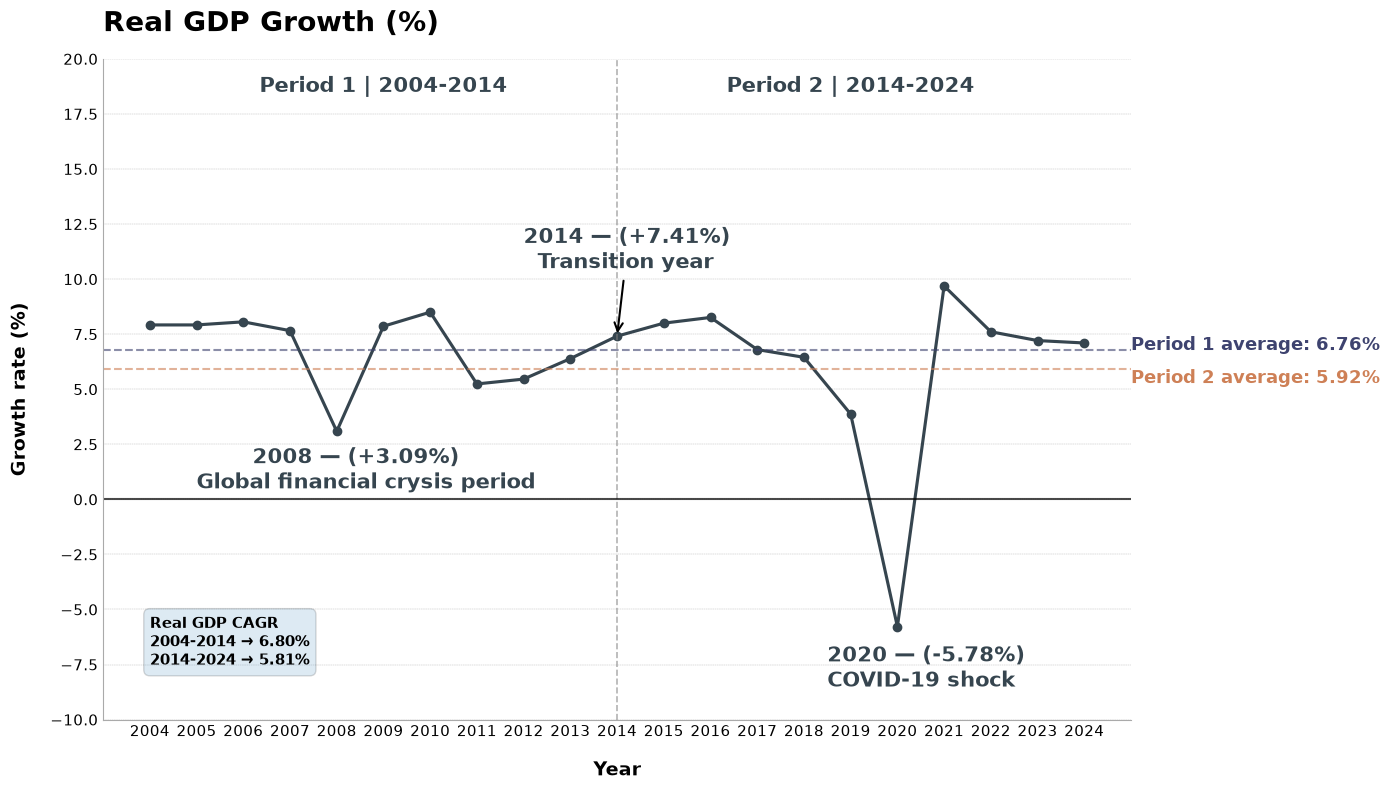

In [54]:
# Create the Figure and Axes
fig, ax = plt.subplots(figsize=(14, 8))

ax.plot(
    df['Year'],
    df['GDP_Growth(annual%)'],
    color='#36454F',
    linewidth=2.25,
    marker='o',
    markersize=6
)

ax.set_title('Real GDP Growth (%)', fontsize=20, fontweight='bold', pad=20, loc='left')
ax.set_xlabel('Year', fontsize=14, fontweight='bold', labelpad=15)
ax.set_ylabel('Growth rate (%)', fontsize=14, fontweight='bold', labelpad=15)

# Clean up the ticks
ax.tick_params(axis='x', which='major', labelsize=11, length=0)
ax.tick_params(axis='y', which='major', labelsize=11, length=0)
ax.set_xticks(df['Year'])

# setting the Y-axis limit.
ax.set_ylim(-10, 14)
ax.set_yticks([-10.0, -7.5, -5.0, -2.5, 0, 2.5, 5.0, 7.5, 10.0, 12.5, 15.0, 17.5, 20.0 ])

# Removing the spines of top and right side for professional touch.
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.spines['left'].set_color('#aaaaaa')
ax.spines['bottom'].set_color('#aaaaaa')

# Adding a subtle grid, "zorder" will push the grid line under the line plot.
ax.grid(axis='y', linestyle='--', linewidth=0.3, zorder=0)

ax.annotate(
    f'{' '*8}2008 — (+3.09%)\nGlobal financial crysis period',
    xy=(2008, 3.09),
    xytext=(2005, 0.5),
    color='#36454F',
    fontsize=15,
    fontweight='bold'
)

ax.annotate(
    '2014 — (+7.41%)\n  Transition year',
    xy=(2014, 7.41),
    xytext=(2012, 10.5),
    arrowprops=dict(arrowstyle='->', lw=1.5),
    fontsize=15,
    fontweight='bold',
    color='#36454F'
)

ax.annotate(
    '2020 — (-5.78%)\nCOVID-19 shock',
    xy=(2020, -5.78),
    xytext=(2018.5, -8.5),
    fontsize=15,
    fontweight='bold',
    color='#36454F'
)

# vertical line separating the two period.
ax.axvline(
    x=2014,
    linestyle='--',
    linewidth=1.2,
    color='gray',
    alpha=0.6
)

# Horizontal line for averages.
ax.axhline(
    y=6.76,
    linestyle='--',
    linewidth=1.5,
    color='#3E436F',
    alpha=0.6
)

ax.axhline(
    y=5.92,
    linestyle='--',
    linewidth=1.5,
    color='#CE8056',
    alpha=0.6
)

ax.text(
    2025,
    7.0,
    f'Period 1 average: 6.76%',
    color='#3E436F',
    fontsize=13,
    fontweight='bold',
    va='center'
)

ax.text(
    2025,
    5.5,
    f'Period 2 average: 5.92%',
    color='#CE8056',
    fontsize=13,
    fontweight='bold',
    va='center'
)

# The 0 percent line.
ax.axhline(
    y=0,
    color='black',
    linewidth=1.5,
    alpha=0.7
)
# Annotation for period 1
ax.annotate(
    'Real GDP CAGR\n2004-2014 → 6.80%\n2014-2024 → 5.81%',
    xy=(2004, -7.5),
    xytext=(2004, -7.5),
    fontsize=11,
    fontweight='bold',
    bbox=dict(boxstyle="round,pad=0.4", alpha=0.15)
)

# Period labels
ax.text(
    2009, 18.5,
    'Period 1 | 2004-2014',
    ha='center',
    fontsize=15,
    fontweight='bold',
    color='#36454F'
)

ax.text(
    2019, 18.5,
    'Period 2 | 2014-2024',
    ha='center',
    fontsize=15,
    fontweight='bold',
    color='#36454F',
)


plt.tight_layout()
plt.show()